# Classroom Reinforcement Learning API

A reusable notebook API for teaching and experimenting with Q-learning and Deep Q-Networks (DQN).

Supported environments:
- FrozenLake-v1: tabular Q-learning
- Blackjack-v1: tabular Q-learning
- CartPole-v1: tabular Q-learning after discretizing continuous observations
- ALE/Pacman-v5, ALE/Pong-v5, and ALE/DonkeyKong-v5: image-based DQN

The API includes environment sessions, policy evaluation, learning curves, Q-table visualizations, action charts, and rendered agent runs. Training examples are disabled by default so that Run All defines the API without starting long experiments.

## 1. Install dependencies

Run this cell once in a new environment. Atari games need the optional ALE dependencies and ROM access configured for your machine. Atari DQN training can be compute-intensive; start with a short run to inspect the pipeline.

In [15]:
# pip install "gymnasium[classic-control,atari]>=1.2" numpy matplotlib pillow torch opencv-python

## 2. Imports, environment catalog, and environment factory

Atari observations are converted to four 84-by-84 grayscale frames for DQN. Gymnasium's Atari preprocessing wrapper performs image preprocessing and frame skipping; frame stacking is provided by FrameStackObservation.

In [16]:
from __future__ import annotations

from dataclasses import dataclass
from typing import Any, Callable
import uuid

import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from PIL import Image as PILImage

import torch
from torch import nn
from torch.nn import functional as F

# Register ALE games when the optional package is installed.
ALE_AVAILABLE = False
ALE_IMPORT_ERROR = None
try:
    import ale_py
    gym.register_envs(ale_py)
    ALE_AVAILABLE = True
except Exception as exc:
    ALE_IMPORT_ERROR = str(exc)


ENVIRONMENTS = {
    "FrozenLake-v1": {
        "title": "FrozenLake",
        "kind": "frozenlake",
        "observation_type": "discrete",
        "actions": ["LEFT", "DOWN", "RIGHT", "UP"],
        "algorithms": ["Q-learning"],
        "requires_atari": False,
    },
    "CartPole-v1": {
        "title": "CartPole",
        "kind": "cartpole",
        "observation_type": "continuous_vector",
        "actions": ["PUSH_LEFT", "PUSH_RIGHT"],
        "algorithms": ["Q-learning with discretization"],
        "requires_atari": False,
    },
    "Blackjack-v1": {
        "title": "Blackjack",
        "kind": "blackjack",
        "observation_type": "structured",
        "actions": ["STICK", "HIT"],
        "algorithms": ["Q-learning"],
        "requires_atari": False,
    },
    "ALE/Pacman-v5": {
        "title": "Pac-Man",
        "kind": "atari",
        "observation_type": "image_stack",
        "actions": ["NOOP", "UP", "RIGHT", "LEFT", "DOWN"],
        "algorithms": ["DQN"],
        "requires_atari": True,
    },
     "ALE/MsPacman-v5": {
        "title": "MsPacMan",
        "kind": "atari",
        "observation_type": "rgb",
        "actions": [
            "NOOP", "UP", "RIGHT", "LEFT", "DOWN",
            "UPRIGHT", "UPLEFT", "DOWNRIGHT", "DOWNLEFT",
        ],
        "algorithms": ["dqn"],
        "requires_atari": True,
    },
    "ALE/Pong-v5": {
        "title": "Pong",
        "kind": "atari",
        "observation_type": "image_stack",
        "actions": ["NOOP", "FIRE", "RIGHT", "LEFT", "RIGHTFIRE", "LEFTFIRE"],
        "algorithms": ["DQN"],
        "requires_atari": True,
    },
    "ALE/DonkeyKong-v5": {
        "title": "Donkey Kong",
        "kind": "atari",
        "observation_type": "image_stack",
        "actions": [
            "NOOP", "FIRE", "UP", "RIGHT", "LEFT", "DOWN",
            "UPRIGHT", "UPLEFT", "DOWNRIGHT", "DOWNLEFT",
            "UPFIRE", "RIGHTFIRE", "LEFTFIRE", "DOWNFIRE",
            "UPRIGHTFIRE", "UPLEFTFIRE", "DOWNRIGHTFIRE", "DOWNLEFTFIRE",
        ],
        "algorithms": ["DQN"],
        "requires_atari": True,
    },
}


def list_environments():
    """Return supported environments, action labels, algorithms, and availability."""
    result = []
    for env_id, details in ENVIRONMENTS.items():
        item = {"id": env_id, **details}
        item["available"] = not item["requires_atari"] or ALE_AVAILABLE
        if item["requires_atari"] and not ALE_AVAILABLE:
            item["unavailable_reason"] = ALE_IMPORT_ERROR
        result.append(item)
    return result


class FireOnReset(gym.Wrapper):
    """Take a FIRE action after reset in games that need it to begin."""

    def reset(self, **kwargs):
        observation, info = self.env.reset(**kwargs)
        observation, _, terminated, truncated, _ = self.env.step(1)
        if terminated or truncated:
            observation, info = self.env.reset(**kwargs)
        return observation, info


def build_environment(
    env_id: str,
    is_slippery: bool = False,
    render: bool = True,
) -> gym.Env:
    """Create a supported environment; disable rendering during training."""
    if env_id not in ENVIRONMENTS:
        raise ValueError("Unknown environment. Call list_environments() first.")

    details = ENVIRONMENTS[env_id]
    render_mode = "rgb_array" if render else None

    if details["requires_atari"]:
        if not ALE_AVAILABLE:
            raise RuntimeError(
                "ALE is unavailable. Install the Atari dependencies and configure "
                "ROM access. Import detail: " + str(ALE_IMPORT_ERROR)
            )

        # Disable ALE's built-in frame skip because AtariPreprocessing applies it.
        env = gym.make(
            env_id,
            frameskip=1,
            repeat_action_probability=0.25,
            render_mode=render_mode,
        )
        if env_id == "ALE/DonkeyKong-v5":
            env = FireOnReset(env)

        env = gym.wrappers.AtariPreprocessing(
            env,
            noop_max=30,
            frame_skip=4,
            screen_size=84,
            grayscale_obs=True,
            grayscale_newaxis=False,
            scale_obs=False,
            terminal_on_life_loss=False,
        )
        return gym.wrappers.FrameStackObservation(env, stack_size=4)

    if env_id == "FrozenLake-v1":
        return gym.make(
            env_id,
            is_slippery=is_slippery,
            render_mode=render_mode,
        )
    if env_id == "CartPole-v1":
        return gym.make(env_id, render_mode=render_mode)
    if env_id == "Blackjack-v1":
        return gym.make(env_id, render_mode="ansi" if render else None)

    raise ValueError("No environment constructor is defined for " + env_id)


list_environments()

[{'id': 'FrozenLake-v1',
  'title': 'FrozenLake',
  'kind': 'frozenlake',
  'observation_type': 'discrete',
  'actions': ['LEFT', 'DOWN', 'RIGHT', 'UP'],
  'algorithms': ['Q-learning'],
  'requires_atari': False,
  'available': True},
 {'id': 'CartPole-v1',
  'title': 'CartPole',
  'kind': 'cartpole',
  'observation_type': 'continuous_vector',
  'actions': ['PUSH_LEFT', 'PUSH_RIGHT'],
  'algorithms': ['Q-learning with discretization'],
  'requires_atari': False,
  'available': True},
 {'id': 'Blackjack-v1',
  'title': 'Blackjack',
  'kind': 'blackjack',
  'observation_type': 'structured',
  'actions': ['STICK', 'HIT'],
  'algorithms': ['Q-learning'],
  'requires_atari': False,
  'available': True},
 {'id': 'ALE/Pacman-v5',
  'title': 'Pac-Man',
  'kind': 'atari',
  'observation_type': 'image_stack',
  'actions': ['NOOP', 'UP', 'RIGHT', 'LEFT', 'DOWN'],
  'algorithms': ['DQN'],
  'requires_atari': True,
  'available': True},
 {'id': 'ALE/MsPacman-v5',
  'title': 'MsPacMan',
  'kind': 'a

## 3. Session API for manual play, random baselines, and rendering

A session keeps one environment open so students can inspect observations, take individual actions, or run a policy. Rendered frames are displayed inside the notebook.

In [17]:
@dataclass
class EnvironmentSession:
    session_id: str
    env_id: str
    env: gym.Env
    observation: Any
    seed: int | None = None
    episode_number: int = 1
    episode_return: float = 0.0
    episode_length: int = 0
    done: bool = False
    last_transition: dict[str, Any] | None = None


SESSIONS: dict[str, EnvironmentSession] = {}
MAX_ACTIVE_SESSIONS = 64


def _session(session_id: str) -> EnvironmentSession:
    if session_id not in SESSIONS:
        raise KeyError("Session not found or already closed: " + session_id)
    return SESSIONS[session_id]


def _session_summary(session: EnvironmentSession) -> dict[str, Any]:
    return {
        "session_id": session.session_id,
        "env_id": session.env_id,
        "title": ENVIRONMENTS[session.env_id]["title"],
        "episode_number": session.episode_number,
        "episode_return": session.episode_return,
        "episode_length": session.episode_length,
        "done": session.done,
        "observation": session.observation,
        "last_transition": session.last_transition,
        "action_names": ENVIRONMENTS[session.env_id]["actions"],
    }


def create_session(
    env_id: str = "FrozenLake-v1",
    seed: int | None = None,
    is_slippery: bool = False,
) -> dict[str, Any]:
    """Create a rendered session and return its ID and initial observation."""
    if len(SESSIONS) >= MAX_ACTIVE_SESSIONS:
        raise RuntimeError("Session limit reached. Close unused sessions first.")

    env = build_environment(env_id, is_slippery=is_slippery, render=True)
    observation, _ = env.reset(seed=seed)
    if seed is not None:
        env.action_space.seed(seed)

    session_id = str(uuid.uuid4())
    SESSIONS[session_id] = EnvironmentSession(
        session_id=session_id,
        env_id=env_id,
        env=env,
        observation=observation,
        seed=seed,
    )
    return _session_summary(SESSIONS[session_id])


def get_session(session_id: str) -> dict[str, Any]:
    """Inspect one session, including its raw observation."""
    return _session_summary(_session(session_id))


def list_sessions() -> list[dict[str, Any]]:
    """List active sessions without returning large image observations."""
    return [
        {
            "session_id": item.session_id,
            "env_id": item.env_id,
            "episode_number": item.episode_number,
            "episode_return": item.episode_return,
            "episode_length": item.episode_length,
            "done": item.done,
        }
        for item in SESSIONS.values()
    ]


def reset_session(session_id: str, seed: int | None = None) -> dict[str, Any]:
    """Start another episode in an existing session."""
    session = _session(session_id)
    observation, _ = session.env.reset(seed=seed)
    if seed is not None:
        session.env.action_space.seed(seed)

    session.observation = observation
    session.episode_number += 1
    session.episode_return = 0.0
    session.episode_length = 0
    session.done = False
    session.seed = seed
    session.last_transition = None
    return _session_summary(session)


def step_session(
    session_id: str,
    action: int | None = None,
    policy: str = "manual",
) -> dict[str, Any]:
    """Take one manual or random action and return the resulting transition."""
    session = _session(session_id)
    if session.done:
        raise RuntimeError("Episode ended. Call reset_session() before stepping again.")

    if policy == "random":
        action = int(session.env.action_space.sample())
    elif policy == "manual":
        if action is None:
            raise ValueError("Supply action when policy='manual'.")
        action = int(action)
    else:
        raise ValueError("policy must be 'manual' or 'random'.")

    if not session.env.action_space.contains(action):
        raise ValueError("Action is outside this environment's action space.")

    observation, reward, terminated, truncated, info = session.env.step(action)
    session.observation = observation
    session.episode_return += float(reward)
    session.episode_length += 1
    session.done = bool(terminated or truncated)

    names = ENVIRONMENTS[session.env_id]["actions"]
    action_name = names[action] if action < len(names) else "ACTION_" + str(action)
    session.last_transition = {
        "action": action,
        "action_name": action_name,
        "policy": policy,
        "reward": float(reward),
        "terminated": bool(terminated),
        "truncated": bool(truncated),
        "info": info,
    }
    return {
        **_session_summary(session),
        "transition": session.last_transition,
    }


def display_current(session_id: str):
    """Display the current rendered frame or text state."""
    session = _session(session_id)
    rendered = session.env.render()

    if isinstance(rendered, str):
        display(rendered)
    elif isinstance(rendered, np.ndarray):
        if rendered.ndim == 2:
            plt.figure(figsize=(6, 4))
            plt.imshow(rendered, cmap="gray")
            plt.axis("off")
            plt.show()
        else:
            display(PILImage.fromarray(rendered.astype(np.uint8)))
    else:
        print("This environment did not return a displayable frame.")


def close_session(session_id: str):
    """Close one session and release its environment resources."""
    session = SESSIONS.pop(session_id, None)
    if session is None:
        raise KeyError("Session not found or already closed: " + session_id)
    session.env.close()


def close_all_sessions():
    """Close all active sessions."""
    for session_id in list(SESSIONS):
        close_session(session_id)

## 4. Run policies and evaluate agents

Policies use one shared callback signature: observation plus action space in, integer action out. Evaluation creates fresh, non-rendered episodes and reports returns, lengths, and a configurable success rate.

In [18]:
Policy = Callable[[Any, gym.spaces.Space], int]


def random_policy(observation: Any, action_space: gym.spaces.Space) -> int:
    """Baseline policy that samples a legal action."""
    return int(action_space.sample())


def run_agent(
    session_id: str,
    policy_fn: Policy,
    max_steps: int = 1000,
    render_every: int = 0,
    seed: int | None = None,
) -> dict[str, Any]:
    """Run a policy in an existing session; optionally render every N steps."""
    session = _session(session_id)
    reset_session(session_id, seed=seed)
    action_log = []

    for step_index in range(max_steps):
        action = int(policy_fn(session.observation, session.env.action_space))
        transition = step_session(session_id, action=action)
        action_log.append({
            "step": step_index + 1,
            "action": transition["transition"]["action"],
            "action_name": transition["transition"]["action_name"],
            "reward": transition["transition"]["reward"],
            "terminated": transition["transition"]["terminated"],
            "truncated": transition["transition"]["truncated"],
        })

        if render_every and (
            (step_index + 1) % render_every == 0 or session.done
        ):
            display_current(session_id)
        if session.done:
            break

    result = {
        "session_id": session_id,
        "env_id": session.env_id,
        "episode_return": session.episode_return,
        "episode_length": session.episode_length,
        "done": session.done,
        "reached_step_limit": (
            not session.done and session.episode_length >= max_steps
        ),
        "steps": action_log,
    }

    # Show the last state even when the step limit is reached between render intervals.
    if render_every and not session.done and session.episode_length % render_every:
        display_current(session_id)
    return result


def evaluate_agent(
    env_id: str,
    policy_fn: Policy,
    episodes: int = 20,
    seed: int | None = None,
    is_slippery: bool = False,
    max_steps: int = 1000,
    success_threshold: float | None = None,
) -> dict[str, Any]:
    """Evaluate a policy without rendering. Default success means return > 0."""
    if episodes < 1 or max_steps < 1:
        raise ValueError("episodes and max_steps must be positive.")

    env = build_environment(env_id, is_slippery=is_slippery, render=False)
    returns, lengths = [], []
    try:
        if seed is not None:
            env.action_space.seed(seed)

        for episode in range(episodes):
            episode_seed = seed + episode if seed is not None else None
            observation, _ = env.reset(seed=episode_seed)
            total_reward = 0.0

            for step_index in range(max_steps):
                action = int(policy_fn(observation, env.action_space))
                if not env.action_space.contains(action):
                    raise ValueError("Policy returned an illegal action.")
                observation, reward, terminated, truncated, _ = env.step(action)
                total_reward += float(reward)
                if terminated or truncated:
                    break

            returns.append(total_reward)
            lengths.append(step_index + 1)
    finally:
        env.close()

    return {
        "env_id": env_id,
        "episodes": episodes,
        "mean_return": float(np.mean(returns)),
        "return_std": float(np.std(returns)),
        "success_rate": float(np.mean(
            np.asarray(returns) >= success_threshold
            if success_threshold is not None
            else np.asarray(returns) > 0
        )),
        "success_threshold": success_threshold,
        "returns": returns,
        "lengths": lengths,
    }

## 5. Tabular Q-learning for FrozenLake, Blackjack, and CartPole

FrozenLake has integer states and Blackjack has small structured states. CartPole has continuous values, so the default encoder bins its four measurements before storing them in a Q-table. The encoder is returned with the training result and reused by the learned policy.

In [19]:
def encode_state(value: Any):
    """Convert common Gymnasium observations into hashable dictionary keys."""
    if isinstance(value, np.ndarray):
        return tuple(encode_state(item) for item in value.tolist())
    if isinstance(value, np.generic):
        return value.item()
    if isinstance(value, dict):
        return tuple(sorted((key, encode_state(item)) for key, item in value.items()))
    if isinstance(value, (tuple, list)):
        return tuple(encode_state(item) for item in value)
    return value


CARTPOLE_BOUNDS = (
    (-2.4, 2.4),         # cart position
    (-3.0, 3.0),         # cart velocity
    (-0.2095, 0.2095),   # pole angle, approximately +/- 12 degrees
    (-3.5, 3.5),         # pole angular velocity
)
DEFAULT_CARTPOLE_BINS = (6, 6, 12, 12)


def make_cartpole_encoder(bins=DEFAULT_CARTPOLE_BINS):
    """Return an encoder that maps CartPole observations to four bin indexes."""
    if len(bins) != 4 or any(int(n) != n or n < 1 for n in bins):
        raise ValueError("bins must contain four positive integers.")

    bins = tuple(int(n) for n in bins)
    edges = tuple(
        np.linspace(low, high, count + 1)[1:-1]
        for (low, high), count in zip(CARTPOLE_BOUNDS, bins)
    )
    bounds = np.asarray(CARTPOLE_BOUNDS, dtype=float)

    def encoder(observation):
        values = np.asarray(observation, dtype=float)
        if values.shape != (4,):
            raise ValueError("CartPole observations must have four values.")
        values = np.clip(values, bounds[:, 0], bounds[:, 1])
        return tuple(
            int(np.digitize(value, edge))
            for value, edge in zip(values, edges)
        )

    return encoder


def train_q_learning(
    env_id: str = "FrozenLake-v1",
    episodes: int = 5000,
    learning_rate: float = 0.1,
    discount_factor: float = 0.95,
    epsilon: float = 1.0,
    minimum_epsilon: float = 0.05,
    epsilon_decay: float = 0.999,
    seed: int | None = 42,
    is_slippery: bool = False,
    max_steps: int = 1000,
    state_encoder: Callable[[Any], Any] | None = None,
    cartpole_bins=DEFAULT_CARTPOLE_BINS,
) -> dict[str, Any]:
    """Train tabular Q-learning; pass a custom state encoder if needed."""
    if env_id not in ENVIRONMENTS:
        raise ValueError("Unsupported environment ID.")
    if ENVIRONMENTS[env_id]["requires_atari"]:
        raise ValueError("Use train_dqn() for ALE games.")
    if episodes < 1 or max_steps < 1:
        raise ValueError("episodes and max_steps must be positive.")
    if not 0 <= minimum_epsilon <= epsilon <= 1:
        raise ValueError("Require 0 <= minimum_epsilon <= epsilon <= 1.")
    if not 0 < epsilon_decay <= 1:
        raise ValueError("epsilon_decay must be in (0, 1].")

    if state_encoder is None:
        state_encoder = (
            make_cartpole_encoder(cartpole_bins)
            if env_id == "CartPole-v1"
            else encode_state
        )

    env = build_environment(
        env_id,
        is_slippery=is_slippery,
        render=False,
    )
    if not isinstance(env.action_space, gym.spaces.Discrete):
        env.close()
        raise TypeError("Tabular Q-learning requires a discrete action space.")

    q_values: dict[Any, np.ndarray] = {}
    rng = np.random.default_rng(seed)
    if seed is not None:
        env.action_space.seed(seed)

    returns, lengths, epsilons = [], [], []
    try:
        for episode in range(episodes):
            episode_seed = seed if episode == 0 else None
            observation, _ = env.reset(seed=episode_seed)
            total_reward = 0.0

            for step_index in range(max_steps):
                state = state_encoder(observation)
                if state not in q_values:
                    q_values[state] = np.zeros(
                        env.action_space.n,
                        dtype=np.float32,
                    )

                # Epsilon-greedy exploration and exploitation.
                if rng.random() < epsilon:
                    action = int(env.action_space.sample())
                else:
                    action = int(np.argmax(q_values[state]))

                next_observation, reward, terminated, truncated, _ = env.step(action)
                next_state = state_encoder(next_observation)
                if next_state not in q_values:
                    q_values[next_state] = np.zeros(
                        env.action_space.n,
                        dtype=np.float32,
                    )

                # Bootstrap through time-limit truncation, but not true termination.
                if terminated:
                    target = float(reward)
                else:
                    target = float(reward) + discount_factor * float(
                        np.max(q_values[next_state])
                    )

                q_values[state][action] += learning_rate * (
                    target - q_values[state][action]
                )
                total_reward += float(reward)
                observation = next_observation

                if terminated or truncated:
                    break

            returns.append(total_reward)
            lengths.append(step_index + 1)
            epsilons.append(epsilon)
            epsilon = max(minimum_epsilon, epsilon * epsilon_decay)
    finally:
        env.close()

    return {
        "env_id": env_id,
        "q_values": q_values,
        "state_encoder": state_encoder,
        "returns": returns,
        "lengths": lengths,
        "epsilons": epsilons,
        "episodes": episodes,
        "seed": seed,
        "is_slippery": is_slippery,
        "cartpole_bins": cartpole_bins if env_id == "CartPole-v1" else None,
    }


def make_q_policy(
    q_values: dict[Any, np.ndarray],
    state_encoder: Callable[[Any], Any] = encode_state,
    epsilon: float = 0.0,
    seed: int | None = None,
) -> Policy:
    """Convert learned Q values into a callback accepted by run_agent()."""
    rng = np.random.default_rng(seed)

    def policy_fn(observation: Any, action_space: gym.spaces.Space) -> int:
        state = state_encoder(observation)
        row = q_values.get(state)
        if row is None:
            return int(action_space.sample())
        if rng.random() < epsilon:
            return int(action_space.sample())
        best_actions = np.flatnonzero(row == np.max(row))
        return int(rng.choice(best_actions))

    return policy_fn


def build_q_agent(env_id: str = "FrozenLake-v1", **training_options) -> dict[str, Any]:
    """Train Q-learning and package its policy for evaluation and rendering."""
    history = train_q_learning(env_id=env_id, **training_options)
    seed = history["seed"]
    policy_seed = seed + 1 if seed is not None else None
    policy = make_q_policy(
        history["q_values"],
        state_encoder=history["state_encoder"],
        seed=policy_seed,
    )
    return {
        "algorithm": "q_learning",
        "env_id": env_id,
        "q_values": history["q_values"],
        "state_encoder": history["state_encoder"],
        "history": history,
        "policy": policy,
        "is_slippery": history["is_slippery"],
    }


def plot_training_history(history: dict[str, Any], window: int = 100):
    """Plot episode returns and their rolling average."""
    values = history.get("returns", history.get("episode_returns", []))
    returns = np.asarray(values, dtype=float)
    if returns.size == 0:
        print("No completed episodes to plot.")
        return None

    window = max(1, min(window, returns.size))
    rolling = np.convolve(returns, np.ones(window) / window, mode="valid")
    x = np.arange(window - 1, returns.size)

    fig, ax = plt.subplots(figsize=(10, 4))
    ax.plot(returns, alpha=0.25, label="Episode return")
    ax.plot(x, rolling, linewidth=2, label=f"{window}-episode rolling mean")
    ax.set_xlabel("Episode")
    ax.set_ylabel("Return")
    ax.set_title(f"{history.get('env_id', 'Agent')} training progress")
    ax.grid(alpha=0.25)
    ax.legend()
    plt.tight_layout()
    plt.show()
    return fig, ax


def plot_epsilon_history(history: dict[str, Any]):
    """Plot how epsilon changes during Q-learning."""
    epsilons = np.asarray(history.get("epsilons", []), dtype=float)
    if epsilons.size == 0:
        print("This history has no epsilon values.")
        return None

    fig, ax = plt.subplots(figsize=(9, 3))
    ax.plot(epsilons)
    ax.set_xlabel("Episode")
    ax.set_ylabel("Epsilon")
    ax.set_title("Exploration rate during training")
    ax.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()
    return fig, ax

## 6. Visualize learned policies and evaluation results

These plots help compare training runs and inspect what the table-based agents learned. Use the plot that matches the environment and agent type.

In [20]:
def plot_evaluation_results(results: dict[str, Any], title: str | None = None):
    """Plot per-episode evaluation returns and the return distribution."""
    returns = np.asarray(results["returns"], dtype=float)
    lengths = np.asarray(results["lengths"], dtype=float)

    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].plot(np.arange(1, len(returns) + 1), returns, marker="o", ms=3)
    axes[0].set_xlabel("Evaluation episode")
    axes[0].set_ylabel("Return")
    axes[0].set_title("Episode returns")

    axes[1].hist(returns, bins=min(20, max(5, len(returns))))
    axes[1].set_xlabel("Return")
    axes[1].set_ylabel("Episode count")
    axes[1].set_title("Return distribution")

    heading = title or results["env_id"]
    fig.suptitle(
        f"{heading}: mean={results['mean_return']:.2f}, "
        f"success={results['success_rate']:.0%}"
    )
    plt.tight_layout()
    plt.show()
    return fig, axes


def plot_action_distribution(run_result: dict[str, Any]):
    """Show which actions a policy selected during a rendered or logged run."""
    steps = run_result.get("steps", [])
    if not steps:
        print("No action steps were recorded.")
        return None

    labels, counts = np.unique(
        [step["action_name"] for step in steps],
        return_counts=True,
    )
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.bar(labels, counts)
    ax.set_xlabel("Action")
    ax.set_ylabel("Count")
    ax.set_title(f"Action choices in {run_result['env_id']}")
    ax.tick_params(axis="x", rotation=35)
    plt.tight_layout()
    plt.show()
    return fig, ax


def plot_frozenlake_policy(agent: dict[str, Any], is_slippery: bool = False):
    """Draw the greedy action in each FrozenLake tile."""
    env = build_environment(
        "FrozenLake-v1",
        is_slippery=is_slippery,
        render=False,
    )
    try:
        base = env.unwrapped
        rows, cols = base.desc.shape
        desc = base.desc
        arrows = ["←", "↓", "→", "↑"]
        values = np.zeros((rows, cols), dtype=float)

        fig, ax = plt.subplots(figsize=(5, 5))
        ax.imshow(values, cmap="Blues", vmin=0, vmax=1)
        for state in range(rows * cols):
            row_index, col_index = divmod(state, cols)
            tile = desc[row_index, col_index]
            tile = tile.decode("utf-8") if isinstance(tile, bytes) else str(tile)
            q_row = agent["q_values"].get(state)
            arrow = arrows[int(np.argmax(q_row))] if q_row is not None else "?"
            label = tile.upper() if tile.upper() in {"S", "H", "G"} else "F"
            ax.text(
                col_index,
                row_index,
                f"{label}\n{arrow}",
                ha="center",
                va="center",
                fontsize=15,
                color="black",
            )
        ax.set_xticks(np.arange(cols))
        ax.set_yticks(np.arange(rows))
        ax.set_title("FrozenLake greedy policy\nS=start, H=hole, G=goal")
        ax.grid(color="black", linewidth=1)
        plt.tight_layout()
        plt.show()
        return fig, ax
    finally:
        env.close()


def plot_blackjack_policy(agent: dict[str, Any]):
    """Plot Blackjack's greedy action for hands with and without a usable ace."""
    q_values = agent["q_values"]
    dealer_cards = range(1, 11)
    player_totals = range(12, 22)
    action_names = ["STICK", "HIT"]

    fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
    for axis, usable_ace in zip(axes, [True, False]):
        matrix = np.zeros((len(player_totals), len(dealer_cards)), dtype=int)
        for r, player_total in enumerate(player_totals):
            for c, dealer_card in enumerate(dealer_cards):
                row = q_values.get((player_total, dealer_card, usable_ace))
                matrix[r, c] = int(np.argmax(row)) if row is not None else 0

        axis.imshow(matrix, cmap="coolwarm", vmin=0, vmax=1, aspect="auto")
        axis.set_xticks(range(10), labels=list(dealer_cards))
        axis.set_yticks(range(10), labels=list(player_totals))
        axis.set_xlabel("Dealer showing")
        axis.set_title("Usable ace" if usable_ace else "No usable ace")
        for r in range(10):
            for c in range(10):
                axis.text(c, r, action_names[matrix[r, c]], ha="center", va="center", fontsize=7)
    axes[0].set_ylabel("Player total")
    fig.suptitle("Blackjack greedy policy")
    plt.tight_layout()
    plt.show()
    return fig, axes


def plot_cartpole_policy_slice(
    agent: dict[str, Any],
    cart_velocity_bin: int | None = None,
    angular_velocity_bin: int | None = None,
):
    """Plot left/right actions over position and pole-angle bins."""
    bins = tuple(agent["history"]["cartpole_bins"])
    velocity_bin = cart_velocity_bin if cart_velocity_bin is not None else bins[1] // 2
    spin_bin = angular_velocity_bin if angular_velocity_bin is not None else bins[3] // 2
    grid = np.zeros((bins[2], bins[0]), dtype=int)

    for angle_bin in range(bins[2]):
        for position_bin in range(bins[0]):
            state = (position_bin, velocity_bin, angle_bin, spin_bin)
            row = agent["q_values"].get(state)
            grid[angle_bin, position_bin] = int(np.argmax(row)) if row is not None else 0

    fig, ax = plt.subplots(figsize=(8, 5))
    ax.imshow(grid, origin="lower", cmap="coolwarm", vmin=0, vmax=1, aspect="auto")
    ax.set_xlabel("Cart position bin")
    ax.set_ylabel("Pole angle bin")
    ax.set_title(
        f"CartPole action slice (velocity bin {velocity_bin}, "
        f"angular velocity bin {spin_bin})"
    )
    colorbar = fig.colorbar(ax.images[0], ax=ax, ticks=[0, 1])
    colorbar.ax.set_yticklabels(["Push left", "Push right"])
    plt.tight_layout()
    plt.show()
    return fig, ax

## 7. Deep Q-Network for Atari games

The DQN implementation uses replay memory, a target network, epsilon-greedy actions, Huber loss, and gradient clipping. DQN accepts the three ALE game IDs in the environment catalog. The replay buffer stores frames compactly rather than duplicating every four-frame stack.

In [21]:
def _atari_stack_chw(observation: Any) -> np.ndarray:
    """Return four grayscale Atari frames with shape (4, 84, 84)."""
    frames = np.asarray(observation, dtype=np.uint8)
    if frames.ndim != 3:
        raise ValueError("Expected a three-dimensional stacked Atari observation.")
    if frames.shape[0] == 4 and frames.shape[1:] == (84, 84):
        return frames
    if frames.shape[-1] == 4 and frames.shape[:2] == (84, 84):
        return np.moveaxis(frames, -1, 0)
    raise ValueError("Expected four 84-by-84 grayscale frames; got " + str(frames.shape))


class AtariReplayBuffer:
    """Replay buffer that stores one current and one next frame per transition."""

    def __init__(self, capacity: int = 10_000, seed: int | None = None):
        if capacity < 4:
            raise ValueError("capacity must be at least four.")
        self.capacity = capacity
        self.frames = np.zeros((capacity, 84, 84), dtype=np.uint8)
        self.next_frames = np.zeros_like(self.frames)
        self.actions = np.zeros(capacity, dtype=np.int64)
        self.rewards = np.zeros(capacity, dtype=np.float32)
        self.terminated = np.zeros(capacity, dtype=np.float32)
        self.episode_ids = np.zeros(capacity, dtype=np.int64)
        self.episode_start_indices = np.zeros(capacity, dtype=np.int64)
        self.valid = np.zeros(capacity, dtype=bool)
        self.position = 0
        self.size = 0
        self.rng = np.random.default_rng(seed)
        self.current_episode_id = None
        self.current_episode_start = 0

    def add(self, state, action, reward, next_state, terminated, episode_id):
        index = self.position
        if self.current_episode_id != episode_id:
            self.current_episode_id = episode_id
            self.current_episode_start = index

        self.frames[index] = _atari_stack_chw(state)[-1]
        self.next_frames[index] = _atari_stack_chw(next_state)[-1]
        self.actions[index] = action
        self.rewards[index] = reward
        self.terminated[index] = float(terminated)
        self.episode_ids[index] = episode_id
        self.episode_start_indices[index] = self.current_episode_start
        self.valid[index] = True

        self.position = (index + 1) % self.capacity
        self.size = min(self.size + 1, self.capacity)

    def _state_at(self, index):
        """Rebuild this transition's stack without crossing episode boundaries."""
        result = np.empty((4, 84, 84), dtype=np.uint8)
        episode_id = self.episode_ids[index]
        start_index = self.episode_start_indices[index]
        can_pad = (
            self.valid[start_index]
            and self.episode_ids[start_index] == episode_id
        )

        for output_channel, lag in enumerate(range(3, -1, -1)):
            previous_index = (index - lag) % self.capacity
            same_episode = (
                self.valid[previous_index]
                and self.episode_ids[previous_index] == episode_id
            )
            if same_episode:
                result[output_channel] = self.frames[previous_index]
            elif can_pad:
                result[output_channel] = self.frames[start_index]
            else:
                result[output_channel] = 0
        return result

    def sample(self, batch_size):
        valid_indices = np.flatnonzero(self.valid)
        if len(valid_indices) < batch_size:
            raise ValueError("Not enough transitions in replay memory.")
        indices = self.rng.choice(valid_indices, size=batch_size, replace=False)
        states = np.stack([self._state_at(int(index)) for index in indices])
        next_states = np.stack([
            np.concatenate(
                (states[row, 1:], self.next_frames[index][None, :, :]),
                axis=0,
            )
            for row, index in enumerate(indices)
        ])
        return (
            states,
            self.actions[indices].copy(),
            self.rewards[indices].copy(),
            next_states,
            self.terminated[indices].copy(),
        )


class AtariQNetwork(nn.Module):
    """Convolutional Q-network for 4 x 84 x 84 image stacks."""

    def __init__(self, action_count: int):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(4, 32, kernel_size=8, stride=4),
            nn.ReLU(),
            nn.Conv2d(32, 64, kernel_size=4, stride=2),
            nn.ReLU(),
            nn.Conv2d(64, 64, kernel_size=3, stride=1),
            nn.ReLU(),
            nn.Flatten(),
        )
        self.values = nn.Sequential(
            nn.Linear(64 * 7 * 7, 512),
            nn.ReLU(),
            nn.Linear(512, action_count),
        )

    def forward(self, frames):
        frames = frames.float() / 255.0
        return self.values(self.features(frames))


def train_dqn(
    env_id: str = "ALE/Pong-v5",
    total_steps: int = 100_000,
    replay_capacity: int = 10_000,
    batch_size: int = 32,
    learning_starts: int = 2_000,
    train_frequency: int = 4,
    target_update_interval: int = 5_000,
    gamma: float = 0.99,
    learning_rate: float = 1e-4,
    epsilon_start: float = 1.0,
    epsilon_end: float = 0.1,
    epsilon_decay_steps: int = 50_000,
    clip_rewards: bool = True,
    seed: int | None = 42,
    device: str | None = None,
    progress_every: int = 10_000,
    env_factory: Callable[[], gym.Env] | None = None,
) -> dict[str, Any]:
    """Train image-based DQN on Pac-Man, Pong, or Donkey Kong.

    Pass env_factory to override the training environment (used by the Part 2
    experiment for deterministic transitions, maze modes, and step penalties).
    """
    if env_id not in ENVIRONMENTS or not ENVIRONMENTS[env_id]["requires_atari"]:
        raise ValueError("train_dqn() expects an ALE game ID from list_environments().")
    if total_steps <= 0 or batch_size <= 0 or train_frequency <= 0:
        raise ValueError("total_steps, batch_size, and train_frequency must be positive.")
    if target_update_interval <= 0 or epsilon_decay_steps <= 0:
        raise ValueError("Target-update and epsilon-decay intervals must be positive.")

    env = env_factory() if env_factory is not None else build_environment(env_id, render=False)
    if not isinstance(env.action_space, gym.spaces.Discrete):
        env.close()
        raise TypeError("DQN requires a discrete action space.")

    if seed is not None:
        torch.manual_seed(seed)
        env.action_space.seed(seed)
    rng = np.random.default_rng(seed)
    if device is not None:
        selected_device = torch.device(device)
    elif torch.cuda.is_available():
        selected_device = torch.device("cuda")
    elif getattr(torch.backends, "mps", None) and torch.backends.mps.is_available():
        selected_device = torch.device("mps")
    else:
        selected_device = torch.device("cpu")

    online_net = AtariQNetwork(env.action_space.n).to(selected_device)
    target_net = AtariQNetwork(env.action_space.n).to(selected_device)
    target_net.load_state_dict(online_net.state_dict())
    target_net.eval()
    optimizer = torch.optim.Adam(online_net.parameters(), lr=learning_rate)
    replay = AtariReplayBuffer(capacity=replay_capacity, seed=seed)

    episode_returns, episode_lengths, losses, epsilon_history = [], [], [], []
    observation, _ = env.reset(seed=seed)
    episode_id = 0
    episode_return = 0.0
    episode_length = 0
    latest_epsilon = epsilon_start

    try:
        for step_number in range(1, total_steps + 1):
            fraction = min(1.0, step_number / epsilon_decay_steps)
            latest_epsilon = epsilon_start + fraction * (
                epsilon_end - epsilon_start
            )
            epsilon_history.append(latest_epsilon)

            if rng.random() < latest_epsilon:
                action = int(env.action_space.sample())
            else:
                frames = torch.as_tensor(
                    _atari_stack_chw(observation)[None, ...],
                    dtype=torch.uint8,
                    device=selected_device,
                )
                with torch.no_grad():
                    action = int(online_net(frames).argmax(dim=1).item())

            next_observation, raw_reward, terminated, truncated, _ = env.step(action)
            training_reward = (
                float(np.sign(raw_reward)) if clip_rewards else float(raw_reward)
            )
            replay.add(
                observation,
                action,
                training_reward,
                next_observation,
                terminated,
                episode_id,
            )

            episode_return += float(raw_reward)
            episode_length += 1

            if (
                replay.size >= max(learning_starts, batch_size)
                and step_number % train_frequency == 0
            ):
                states, actions, rewards, next_states, terminal_flags = replay.sample(
                    batch_size
                )
                states_t = torch.as_tensor(
                    states, dtype=torch.uint8, device=selected_device
                )
                actions_t = torch.as_tensor(
                    actions, dtype=torch.int64, device=selected_device
                ).unsqueeze(1)
                rewards_t = torch.as_tensor(
                    rewards, dtype=torch.float32, device=selected_device
                )
                next_states_t = torch.as_tensor(
                    next_states, dtype=torch.uint8, device=selected_device
                )
                terminal_t = torch.as_tensor(
                    terminal_flags, dtype=torch.float32, device=selected_device
                )

                predicted_q = online_net(states_t).gather(1, actions_t).squeeze(1)
                with torch.no_grad():
                    best_next_q = target_net(next_states_t).max(dim=1).values
                    target_q = rewards_t + gamma * (1.0 - terminal_t) * best_next_q

                loss = F.smooth_l1_loss(predicted_q, target_q)
                optimizer.zero_grad(set_to_none=True)
                loss.backward()
                nn.utils.clip_grad_norm_(online_net.parameters(), max_norm=10.0)
                optimizer.step()
                losses.append(float(loss.detach().cpu()))

            if step_number % target_update_interval == 0:
                target_net.load_state_dict(online_net.state_dict())

            observation = next_observation
            if terminated or truncated:
                episode_returns.append(episode_return)
                episode_lengths.append(episode_length)
                observation, _ = env.reset()
                episode_id += 1
                episode_return = 0.0
                episode_length = 0

            if progress_every and step_number % progress_every == 0:
                recent = episode_returns[-10:]
                recent_mean = float(np.mean(recent)) if recent else float("nan")
                print(
                    f"step {step_number:,}/{total_steps:,} | "
                    f"epsilon {latest_epsilon:.3f} | "
                    f"recent mean return {recent_mean:.2f} | "
                    f"replay {replay.size:,}"
                )
    finally:
        env.close()

    history = {
        "env_id": env_id,
        "episode_returns": episode_returns,
        "episode_lengths": episode_lengths,
        "losses": losses,
        "epsilon_by_step": epsilon_history,
        "steps": total_steps,
        "final_epsilon": latest_epsilon,
    }
    return {
        "algorithm": "dqn",
        "env_id": env_id,
        "policy_net": online_net,
        "target_net": target_net,
        "history": history,
        "device": str(selected_device),
    }


def make_dqn_policy(agent: dict[str, Any]) -> Policy:
    """Adapt a trained DQN result into the shared policy callback."""
    if agent.get("algorithm") != "dqn":
        raise ValueError("Expected an agent returned by train_dqn().")

    model = agent["policy_net"]
    model.eval()
    device = torch.device(agent["device"])

    def policy_fn(observation: Any, action_space: gym.spaces.Space) -> int:
        frames = torch.as_tensor(
            _atari_stack_chw(observation)[None, ...],
            dtype=torch.uint8,
            device=device,
        )
        with torch.no_grad():
            return int(model(frames).argmax(dim=1).item())

    return policy_fn


def plot_dqn_history(history: dict[str, Any], window: int = 10):
    """Plot Atari episode returns, rolling average, losses, and epsilon."""
    returns = np.asarray(history.get("episode_returns", []), dtype=float)
    losses = np.asarray(history.get("losses", []), dtype=float)
    epsilon = np.asarray(history.get("epsilon_by_step", []), dtype=float)

    fig, axes = plt.subplots(3, 1, figsize=(10, 9))
    if returns.size:
        axes[0].plot(returns, alpha=0.3, label="Episode return")
        window = max(1, min(window, returns.size))
        rolling = np.convolve(returns, np.ones(window) / window, mode="valid")
        axes[0].plot(
            np.arange(window - 1, returns.size),
            rolling,
            linewidth=2,
            label=f"{window}-episode rolling mean",
        )
        axes[0].legend()
    else:
        axes[0].text(0.5, 0.5, "No completed episodes in this run.", ha="center")
    axes[0].set_ylabel("Return")
    axes[0].set_title("DQN episode returns")

    if losses.size:
        axes[1].plot(losses, alpha=0.8)
    else:
        axes[1].text(0.5, 0.5, "No optimization updates recorded.", ha="center")
    axes[1].set_ylabel("Huber loss")
    axes[1].set_title("DQN optimization loss")

    if epsilon.size:
        axes[2].plot(epsilon)
    axes[2].set_ylabel("Epsilon")
    axes[2].set_xlabel("Environment step")
    axes[2].set_title("DQN exploration schedule")

    for axis in axes:
        axis.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()
    return fig, axes


def get_agent_policy(agent: dict[str, Any]) -> Policy:
    """Return the policy callback stored in a Q agent or build a DQN callback."""
    if agent.get("algorithm") == "q_learning":
        return agent["policy"]
    if agent.get("algorithm") == "dqn":
        return make_dqn_policy(agent)
    if agent.get("algorithm") == "ppo":
        return make_ppo_policy(agent)
    raise ValueError("Unknown agent type.")

## 8. Shared agent evaluation and rendering helpers

Use the same functions for Q-learning and DQN agents. Set render_every to a positive interval to display frames during play. Use 0 to show only the final state.

In [22]:
def evaluate_trained_agent(
    agent: dict[str, Any],
    episodes: int = 20,
    seed: int | None = 100,
    max_steps: int = 10_000,
    success_threshold: float | None = None,
) -> dict[str, Any]:
    """Evaluate either agent type with the common evaluation API."""
    return evaluate_agent(
        env_id=agent["env_id"],
        policy_fn=get_agent_policy(agent),
        episodes=episodes,
        seed=seed,
        is_slippery=agent.get("is_slippery", False),
        max_steps=max_steps,
        success_threshold=success_threshold,
    )


def run_trained_agent(
    agent: dict[str, Any],
    seed: int | None = 2026,
    render_every: int = 25,
    max_steps: int = 10_000,
) -> dict[str, Any]:
    """Render a trained Q-learning or DQN agent through a notebook session."""
    session = create_session(
        env_id=agent["env_id"],
        seed=seed,
        is_slippery=agent.get("is_slippery", False),
    )
    session_id = session["session_id"]

    try:
        result = run_agent(
            session_id=session_id,
            policy_fn=get_agent_policy(agent),
            max_steps=max_steps,
            render_every=render_every,
            seed=seed,
        )
        if render_every == 0:
            display_current(session_id)
        return result
    finally:
        close_session(session_id)

## 9. Examples: Q-learning agents

Change the flag to True to run a demonstration. These examples are independent, so students can run only the environment they are studying.

In [23]:
RUN_FROZENLAKE_DEMO = False
RUN_CARTPOLE_DEMO = False
RUN_BLACKJACK_DEMO = False

if RUN_FROZENLAKE_DEMO:
    lake_agent = build_q_agent(
        "FrozenLake-v1",
        episodes=5000,
        learning_rate=0.8,
        discount_factor=0.95,
        epsilon=1.0,
        minimum_epsilon=0.05,
        epsilon_decay=0.999,
        seed=42,
        is_slippery=False,
        max_steps=100,
    )
    plot_training_history(lake_agent["history"], window=100)
    plot_epsilon_history(lake_agent["history"])
    lake_results = evaluate_trained_agent(
        lake_agent, episodes=100, seed=500, max_steps=100
    )
    plot_evaluation_results(lake_results)
    plot_frozenlake_policy(lake_agent)
    lake_run = run_trained_agent(lake_agent, render_every=1, max_steps=100)
    plot_action_distribution(lake_run)

if RUN_CARTPOLE_DEMO:
    cartpole_agent = build_q_agent(
        "CartPole-v1",
        episodes=5000,
        learning_rate=0.1,
        discount_factor=0.99,
        epsilon=1.0,
        minimum_epsilon=0.05,
        epsilon_decay=0.999,
        cartpole_bins=(6, 6, 12, 12),
        seed=42,
        max_steps=500,
    )
    plot_training_history(cartpole_agent["history"], window=100)
    plot_epsilon_history(cartpole_agent["history"])
    cartpole_results = evaluate_trained_agent(
        cartpole_agent,
        episodes=100,
        seed=500,
        max_steps=500,
        success_threshold=195,
    )
    print("Mean return:", round(cartpole_results["mean_return"], 1))
    print("Success rate (195+ steps):", round(cartpole_results["success_rate"] * 100, 1), "%")
    plot_evaluation_results(cartpole_results)
    plot_cartpole_policy_slice(cartpole_agent)
    cartpole_run = run_trained_agent(
        cartpole_agent, seed=2026, render_every=25, max_steps=500
    )
    plot_action_distribution(cartpole_run)

if RUN_BLACKJACK_DEMO:
    blackjack_agent = build_q_agent(
        "Blackjack-v1",
        episodes=30_000,
        learning_rate=0.1,
        discount_factor=0.95,
        epsilon=1.0,
        minimum_epsilon=0.05,
        epsilon_decay=0.9998,
        seed=42,
        max_steps=100,
    )
    plot_training_history(blackjack_agent["history"], window=500)
    plot_epsilon_history(blackjack_agent["history"])
    blackjack_results = evaluate_trained_agent(
        blackjack_agent, episodes=5000, seed=500, max_steps=100
    )
    plot_evaluation_results(blackjack_results)
    plot_blackjack_policy(blackjack_agent)
    blackjack_run = run_trained_agent(
        blackjack_agent, seed=2026, render_every=1, max_steps=100
    )
    plot_action_distribution(blackjack_run)

## 10. Examples: DQN agents for Atari games

Atari DQN needs many environment steps. Keep these flags False for a quick Run All. For a classroom demonstration, begin with 10,000–50,000 steps to inspect the training process; stronger game performance may require substantially more training and suitable hardware.

In [24]:
RUN_PACMAN_DQN_DEMO = False
RUN_PONG_DQN_DEMO = False
RUN_DONKEYKONG_DQN_DEMO = False

if RUN_PACMAN_DQN_DEMO:
    pacman_agent = train_dqn(
        "ALE/Pacman-v5",
        total_steps=50_000,
        replay_capacity=10_000,
        learning_starts=2_000,
        seed=42,
        progress_every=5_000,
    )
    plot_dqn_history(pacman_agent["history"])
    pacman_results = evaluate_trained_agent(
        pacman_agent, episodes=5, seed=500, max_steps=20_000
    )
    plot_evaluation_results(pacman_results)
    pacman_run = run_trained_agent(
        pacman_agent, seed=2026, render_every=100, max_steps=20_000
    )
    plot_action_distribution(pacman_run)

if RUN_PONG_DQN_DEMO:
    pong_agent = train_dqn(
        "ALE/Pong-v5",
        total_steps=50_000,
        replay_capacity=10_000,
        learning_starts=2_000,
        seed=42,
        progress_every=5_000,
    )
    plot_dqn_history(pong_agent["history"])
    pong_results = evaluate_trained_agent(
        pong_agent, episodes=5, seed=500, max_steps=20_000
    )
    plot_evaluation_results(pong_results)
    pong_run = run_trained_agent(
        pong_agent, seed=2026, render_every=100, max_steps=20_000
    )
    plot_action_distribution(pong_run)

if RUN_DONKEYKONG_DQN_DEMO:
    donkeykong_agent = train_dqn(
        "ALE/DonkeyKong-v5",
        total_steps=50_000,
        replay_capacity=10_000,
        learning_starts=2_000,
        seed=42,
        progress_every=5_000,
    )
    plot_dqn_history(donkeykong_agent["history"])
    donkeykong_results = evaluate_trained_agent(
        donkeykong_agent, episodes=5, seed=500, max_steps=20_000
    )
    plot_evaluation_results(donkeykong_results)
    donkeykong_run = run_trained_agent(
        donkeykong_agent, seed=2026, render_every=100, max_steps=20_000
    )
    plot_action_distribution(donkeykong_run)

## 11. Function quick reference

| Function | Use |
|---|---|
| list_environments() | List supported games, algorithms, actions, and ALE availability. |
| build_environment(env_id, render) | Construct a training or renderable Gymnasium environment. |
| create_session(env_id, seed) | Start a rendered manual-play session. |
| step_session(session_id, action) | Advance one manual action. |
| step_session(session_id, policy="random") | Take one random action. |
| run_agent(session_id, policy_fn, render_every) | Run a callback policy in a session. |
| evaluate_agent(env_id, policy_fn, episodes) | Evaluate any compatible policy. |
| train_q_learning(env_id, ...) | Train tabular Q-learning; automatically discretizes CartPole by default. |
| build_q_agent(env_id, ...) | Train Q-learning and package a policy for the common API. |
| make_q_policy(q_values, state_encoder) | Convert a Q-table to a policy callback. |
| train_dqn(env_id, ...) | Train an image-based DQN for a supported ALE game. |
| make_dqn_policy(agent) | Convert a trained DQN to the common policy callback. |
| evaluate_trained_agent(agent, ...) | Evaluate a packaged Q-learning or DQN agent. |
| run_trained_agent(agent, render_every) | Render a trained agent through the session API. |
| plot_training_history(history) | Plot episode returns and rolling mean. |
| plot_epsilon_history(history) | Visualize Q-learning exploration decay. |
| plot_dqn_history(history) | Plot Atari returns, loss, and epsilon. |
| plot_evaluation_results(results) | Compare episode returns and their distribution. |
| plot_action_distribution(run_result) | Visualize which actions the policy selected. |
| plot_frozenlake_policy(agent) | Draw learned FrozenLake moves on the map. |
| plot_blackjack_policy(agent) | Visualize stick/hit decisions by player and dealer cards. |
| plot_cartpole_policy_slice(agent) | Inspect a slice through the CartPole Q-table. |
| close_session(session_id) / close_all_sessions() | Release environment sessions. |

Notebook sessions live in the current kernel. Restarting the kernel clears them. Close sessions after demonstrations.

In [25]:
# Donkey Kong image-based DQN agent.
# Run RL-API.ipynb first in this Jupyter kernel, then run:
# %run -i agent_06_donkeykong_dqn.py
#
# ALE and Donkey Kong ROM access must be configured. Training is compute-intensive.
"""
TOTAL_TRAINING_STEPS = 50_000
REPLAY_CAPACITY = 10_000
EVALUATION_EPISODES = 3
PLAYBACK_STEPS = 2_000

donkeykong_agent = train_dqn(
    "ALE/DonkeyKong-v5",
    total_steps=TOTAL_TRAINING_STEPS,
    replay_capacity=REPLAY_CAPACITY,
    batch_size=32,
    learning_starts=2_000,
    train_frequency=4,
    target_update_interval=5_000,
    gamma=0.99,
    learning_rate=1e-4,
    epsilon_start=1.0,
    epsilon_end=0.1,
    epsilon_decay_steps=40_000,
    clip_rewards=True,
    seed=42,
    progress_every=5_000,
)

plot_dqn_history(donkeykong_agent["history"], window=10)

donkeykong_results = evaluate_trained_agent(
    donkeykong_agent,
    episodes=EVALUATION_EPISODES,
    seed=500,
    max_steps=10_000,
)
print(f"Mean evaluation return: {donkeykong_results['mean_return']:.2f}")
plot_evaluation_results(donkeykong_results)

donkeykong_playback = run_trained_agent(
    donkeykong_agent,
    seed=2026,
    render_every=100,
    max_steps=PLAYBACK_STEPS,
)
print(
    f"Rendered return: {donkeykong_playback['episode_return']:.1f}; "
    f"steps: {donkeykong_playback['episode_length']}"
)
plot_action_distribution(donkeykong_playback)
"""


'\nTOTAL_TRAINING_STEPS = 50_000\nREPLAY_CAPACITY = 10_000\nEVALUATION_EPISODES = 3\nPLAYBACK_STEPS = 2_000\n\ndonkeykong_agent = train_dqn(\n    "ALE/DonkeyKong-v5",\n    total_steps=TOTAL_TRAINING_STEPS,\n    replay_capacity=REPLAY_CAPACITY,\n    batch_size=32,\n    learning_starts=2_000,\n    train_frequency=4,\n    target_update_interval=5_000,\n    gamma=0.99,\n    learning_rate=1e-4,\n    epsilon_start=1.0,\n    epsilon_end=0.1,\n    epsilon_decay_steps=40_000,\n    clip_rewards=True,\n    seed=42,\n    progress_every=5_000,\n)\n\nplot_dqn_history(donkeykong_agent["history"], window=10)\n\ndonkeykong_results = evaluate_trained_agent(\n    donkeykong_agent,\n    episodes=EVALUATION_EPISODES,\n    seed=500,\n    max_steps=10_000,\n)\nprint(f"Mean evaluation return: {donkeykong_results[\'mean_return\']:.2f}")\nplot_evaluation_results(donkeykong_results)\n\ndonkeykong_playback = run_trained_agent(\n    donkeykong_agent,\n    seed=2026,\n    render_every=100,\n    max_steps=PLAYBACK_S

## Notes for classroom use

- Q-learning is suited to the finite FrozenLake and Blackjack state representations. CartPole needs discretization because its observations are continuous.
- The DQN implementation is an educational baseline for Atari image observations, not a tuned competition agent. Compare seeds and training budgets before drawing conclusions.
- ALE games require the optional Atari package and ROM access. Atari image preprocessing uses Gymnasium's AtariPreprocessing wrapper, and four consecutive frames are combined with FrameStackObservation.
- Separate the training and evaluation seeds. Report mean return, variability, and success rate rather than relying on one rendered episode.
- The notebook API uses Gymnasium's terminated and truncated flags. A true terminal state stops bootstrapping; a time-limit truncation may still bootstrap.

In [26]:
TOTAL_TRAINING_STEPS = 50_000
REPLAY_CAPACITY = 10_000
EVALUATION_EPISODES = 3
PLAYBACK_STEPS = 2_000

pacman_agent = train_dqn(
    "ALE/MsPacman-v5",
    total_steps=TOTAL_TRAINING_STEPS,
    replay_capacity=REPLAY_CAPACITY,
    batch_size=32,
    learning_starts=2_000,
    train_frequency=4,
    target_update_interval=5_000,
    gamma=0.99,
    learning_rate=1e-4,
    epsilon_start=1.0,
    epsilon_end=0.1,
    epsilon_decay_steps=40_000,
    clip_rewards=True,
    seed=42,
    progress_every=5_000,
    device="mps",
)


step 5,000/50,000 | epsilon 0.887 | recent mean return 216.67 | replay 5,000
step 10,000/50,000 | epsilon 0.775 | recent mean return 309.00 | replay 10,000
step 15,000/50,000 | epsilon 0.662 | recent mean return 376.00 | replay 10,000
step 20,000/50,000 | epsilon 0.550 | recent mean return 388.00 | replay 10,000
step 25,000/50,000 | epsilon 0.438 | recent mean return 651.00 | replay 10,000
step 30,000/50,000 | epsilon 0.325 | recent mean return 710.00 | replay 10,000
step 35,000/50,000 | epsilon 0.213 | recent mean return 632.00 | replay 10,000
step 40,000/50,000 | epsilon 0.100 | recent mean return 559.00 | replay 10,000
step 45,000/50,000 | epsilon 0.100 | recent mean return 710.00 | replay 10,000
step 50,000/50,000 | epsilon 0.100 | recent mean return 715.00 | replay 10,000


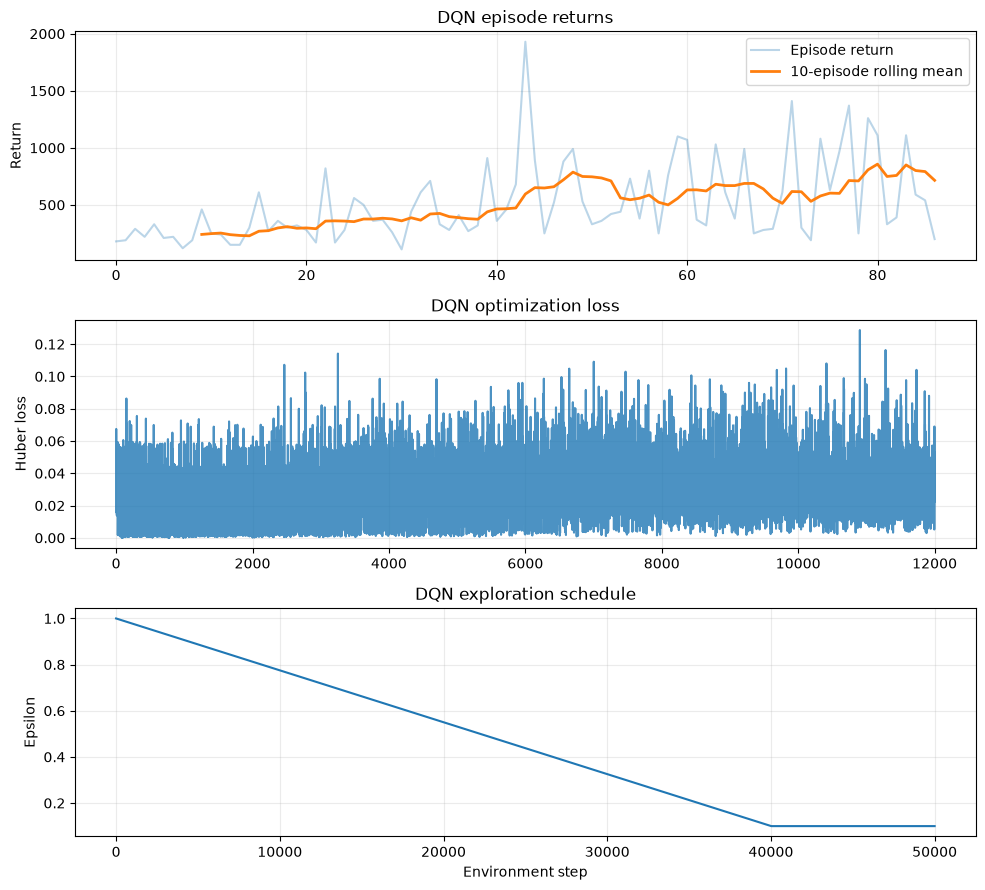

Mean evaluation return: 330.00


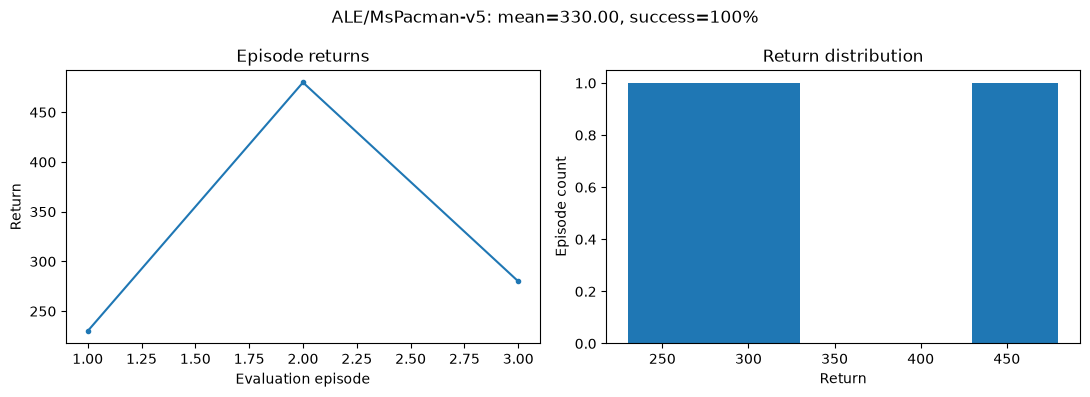

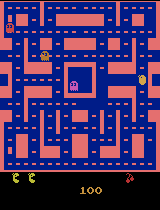

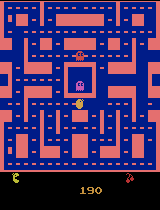

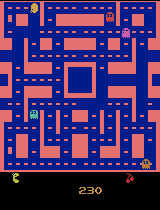

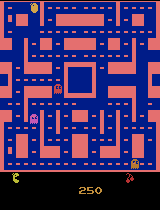

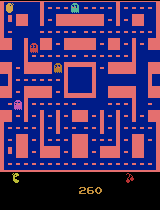

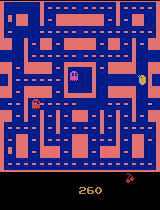

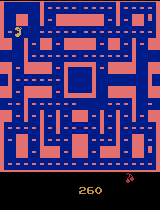

Rendered return: 260.0; steps: 646


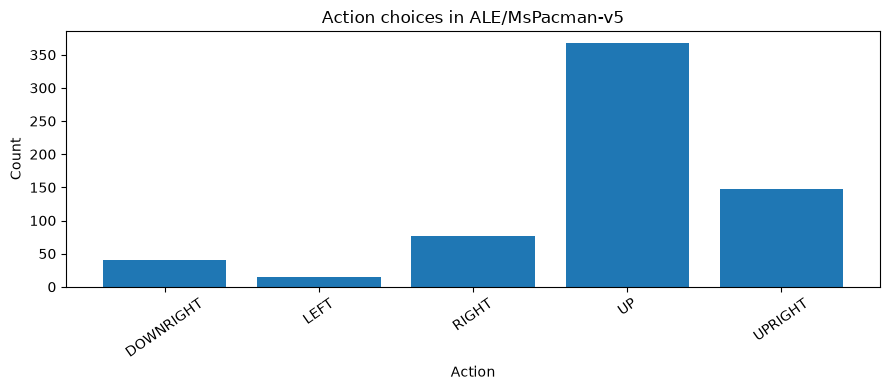

(<Figure size 900x400 with 1 Axes>,
 <Axes: title={'center': 'Action choices in ALE/MsPacman-v5'}, xlabel='Action', ylabel='Count'>)

In [27]:

plot_dqn_history(pacman_agent["history"], window=10)

donkeykong_results = evaluate_trained_agent(
    pacman_agent,
    episodes=EVALUATION_EPISODES,
    seed=500,
    max_steps=10_000,
)
print(f"Mean evaluation return: {donkeykong_results['mean_return']:.2f}")
plot_evaluation_results(donkeykong_results)

donkeykong_playback = run_trained_agent(
    pacman_agent,
    seed=2026,
    render_every=100,
    max_steps=PLAYBACK_STEPS,
)
print(
    f"Rendered return: {donkeykong_playback['episode_return']:.1f}; "
    f"steps: {donkeykong_playback['episode_length']}"
)
plot_action_distribution(donkeykong_playback)

## 12. Part 2 — Compare learning settings (MsPacMan: DQN vs PPO)

Setting DQN (off-policy TD control, the deep form of Q-learning) against PPO
(on-policy actor-critic) under four conditions:

| Setting | What changes | Implementation |
|---|---|---|
| A: Predictable | Deterministic transitions | `repeat_action_probability=0.0` |
| B: Uncertain | Stochastic transitions | `repeat_action_probability=0.25` (ALE default) |
| C: Changed incentives | B + per-step penalty | reward wrapper, small and large penalty |
| D: Transfer | B agents frozen on unseen mazes | train `mode=0`, evaluate `mode` 1-2 |

Conventions (comparison rules):
- Interactions = env steps after frame-skip 4; both algorithms get the same budget.
- Same training-seed list for both algorithms; evaluation uses a separate seed list,
  >=200 episodes, frozen parameters, greedy actions (argmax Q / argmax policy logits).
- Success = episode return >= 2,000 points (prediction-sheet definition).
- Setting C agents are evaluated on the penalty-free B environment so returns stay
  comparable across reward definitions.
- Runtime and hardware are recorded per run.


In [28]:
import time
import platform
import json
from pathlib import Path


class StepPenaltyWrapper(gym.Wrapper):
    """Subtract a fixed penalty from every reward (applied to raw game rewards)."""

    def __init__(self, env: gym.Env, penalty: float):
        super().__init__(env)
        if penalty < 0:
            raise ValueError("penalty must be non-negative.")
        self.penalty = float(penalty)

    def step(self, action):
        observation, reward, terminated, truncated, info = self.env.step(action)
        return observation, reward - self.penalty, terminated, truncated, info


PART2_ENV_ID = "ALE/MsPacman-v5"

# Setting definitions: A deterministic, B stochastic, C = B plus a step penalty.
# Two penalty sizes because the prediction sheet expects size-dependent effects.
PART2_SETTING_PARAMS = {
    "A": {"repeat_action_probability": 0.0, "mode": 0, "step_penalty": 0.0},
    "B": {"repeat_action_probability": 0.25, "mode": 0, "step_penalty": 0.0},
    "C-small": {"repeat_action_probability": 0.25, "mode": 0, "step_penalty": 0.05},
    "C-large": {"repeat_action_probability": 0.25, "mode": 0, "step_penalty": 0.5},
}


def build_part2_environment(
    setting: str = "B",
    mode: int | None = None,
    render: bool = False,
) -> gym.Env:
    """Build MsPacMan with Part 2 knobs, using the same preprocessing as the DQN."""
    if setting not in PART2_SETTING_PARAMS:
        raise ValueError("setting must be one of " + str(sorted(PART2_SETTING_PARAMS)))
    params = PART2_SETTING_PARAMS[setting]
    maze = params["mode"] if mode is None else mode
    env = gym.make(
        PART2_ENV_ID,
        frameskip=1,
        repeat_action_probability=params["repeat_action_probability"],
        mode=maze,
        render_mode="rgb_array" if render else None,
    )
    env = gym.wrappers.AtariPreprocessing(
        env,
        noop_max=30,
        frame_skip=4,
        screen_size=84,
        grayscale_obs=True,
        grayscale_newaxis=False,
        scale_obs=False,
        terminal_on_life_loss=False,
    )
    if params["step_penalty"] > 0:
        env = StepPenaltyWrapper(env, params["step_penalty"])
    return gym.wrappers.FrameStackObservation(env, stack_size=4)


In [29]:
def _part2_device(device: str | None = None) -> torch.device:
    """Pick the best available torch device (explicit > cuda > mps > cpu)."""
    if device is not None:
        return torch.device(device)
    if torch.cuda.is_available():
        return torch.device("cuda")
    if hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")


class PpoActorCritic(nn.Module):
    """Shared CNN trunk with separate actor and critic heads for 4x84x84 stacks."""

    def __init__(self, action_count: int):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(4, 32, kernel_size=8, stride=4), nn.ReLU(),
            nn.Conv2d(32, 64, kernel_size=4, stride=2), nn.ReLU(),
            nn.Conv2d(64, 64, kernel_size=3, stride=1), nn.ReLU(),
            nn.Flatten(),
        )
        self.shared = nn.Sequential(nn.Linear(64 * 7 * 7, 512), nn.ReLU())
        self.actor = nn.Linear(512, action_count)
        self.critic = nn.Linear(512, 1)

    def forward(self, frames):
        hidden = self.shared(self.features(frames.float() / 255.0))
        return self.actor(hidden), self.critic(hidden).squeeze(-1)


def train_ppo(
    env_factory: Callable[[], gym.Env],
    total_steps: int = 100_000,
    seed: int | None = 42,
    device: str | None = None,
    n_steps: int = 512,
    ppo_epochs: int = 4,
    minibatch_size: int = 128,
    learning_rate: float = 2.5e-4,
    gamma: float = 0.99,
    gae_lambda: float = 0.95,
    clip_ratio: float = 0.2,
    value_coef: float = 0.5,
    entropy_coef: float = 0.01,
    max_grad_norm: float = 0.5,
    target_kl: float | None = 0.03,
    max_episode_steps: int = 2_500,
    progress_every: int = 25_000,
) -> dict[str, Any]:
    """Train a CNN PPO agent on MsPacMan; counts interactions like train_dqn()."""
    if total_steps < n_steps:
        raise ValueError("total_steps must be at least n_steps.")
    if minibatch_size < 1 or n_steps % minibatch_size != 0:
        raise ValueError("n_steps must be a positive multiple of minibatch_size.")
    if not 0 < gae_lambda <= 1 or not 0 < clip_ratio < 1:
        raise ValueError("Require 0 < gae_lambda <= 1 and 0 < clip_ratio < 1.")

    selected_device = _part2_device(device)
    env = env_factory()
    if not isinstance(env.action_space, gym.spaces.Discrete):
        env.close()
        raise TypeError("PPO requires a discrete action space.")

    if seed is not None:
        torch.manual_seed(seed)
        env.action_space.seed(seed)
    rng = np.random.default_rng(seed)

    model = PpoActorCritic(env.action_space.n).to(selected_device)
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

    episode_returns: list[float] = []
    episode_lengths: list[int] = []
    episode_steps: list[int] = []
    update_stats: list[dict[str, float]] = []

    observation, _ = env.reset(seed=seed)
    episode_return = 0.0
    episode_length = 0
    total_env_steps = 0
    last_progress = 0
    started = time.perf_counter()

    try:
        while total_env_steps < total_steps:
            obs_buf = np.zeros((n_steps, 4, 84, 84), dtype=np.uint8)
            next_obs_buf = np.zeros((n_steps, 4, 84, 84), dtype=np.uint8)
            act_buf = np.zeros(n_steps, dtype=np.int64)
            logp_buf = np.zeros(n_steps, dtype=np.float32)
            val_buf = np.zeros(n_steps, dtype=np.float32)
            rew_buf = np.zeros(n_steps, dtype=np.float32)
            done_buf = np.zeros(n_steps, dtype=np.float32)
            trunc_buf = np.zeros(n_steps, dtype=np.float32)

            for t in range(n_steps):
                obs_buf[t] = _atari_stack_chw(observation)
                with torch.no_grad():
                    logits, value = model(
                        torch.as_tensor(obs_buf[t][None], device=selected_device)
                    )
                distribution = torch.distributions.Categorical(logits=logits)
                action = distribution.sample()
                act_buf[t] = int(action.item())
                logp_buf[t] = float(distribution.log_prob(action).item())
                val_buf[t] = float(value.item())

                observation, reward, terminated, truncated, _ = env.step(int(act_buf[t]))
                next_obs_buf[t] = _atari_stack_chw(observation)
                total_env_steps += 1
                episode_return += float(reward)
                episode_length += 1
                rew_buf[t] = float(reward)
                done_buf[t] = float(terminated)
                trunc_buf[t] = float(truncated)

                if terminated or truncated or episode_length >= max_episode_steps:
                    episode_returns.append(episode_return)
                    episode_lengths.append(episode_length)
                    episode_steps.append(total_env_steps)
                    observation, _ = env.reset()
                    episode_return = 0.0
                    episode_length = 0

            # Bootstrap values: terminal -> 0, truncation -> V(final obs),
            # rollout end -> V(current obs). Truncations therefore still bootstrap.
            with torch.no_grad():
                final_values = model(
                    torch.as_tensor(next_obs_buf, device=selected_device)
                )[1]
            next_values = np.empty(n_steps, dtype=np.float32)
            for t in range(n_steps):
                if done_buf[t] or trunc_buf[t]:
                    next_values[t] = 0.0 if done_buf[t] else float(final_values[t].item())
                elif t == n_steps - 1:
                    next_values[t] = float(final_values[t].item())
                else:
                    next_values[t] = val_buf[t + 1]

            advantages = np.zeros(n_steps, dtype=np.float32)
            running_gae = 0.0
            for t in reversed(range(n_steps)):
                delta = rew_buf[t] + gamma * next_values[t] - val_buf[t]
                if done_buf[t] or trunc_buf[t]:
                    running_gae = delta
                else:
                    running_gae = delta + gamma * gae_lambda * running_gae
                advantages[t] = running_gae
            returns = advantages + val_buf

            obs_tensor = torch.as_tensor(obs_buf, device=selected_device)
            act_tensor = torch.as_tensor(act_buf, device=selected_device)
            old_logp = torch.as_tensor(logp_buf, device=selected_device)
            adv_tensor = torch.as_tensor(advantages, device=selected_device)
            adv_tensor = (adv_tensor - adv_tensor.mean()) / (adv_tensor.std() + 1e-8)
            ret_tensor = torch.as_tensor(returns, device=selected_device)

            order = rng.permutation(n_steps)
            stop_epochs = False
            for _ in range(ppo_epochs):
                if stop_epochs:
                    break
                for begin in range(0, n_steps, minibatch_size):
                    mb = torch.as_tensor(order[begin:begin + minibatch_size], device=selected_device)
                    logits, values = model(obs_tensor[mb])
                    distribution = torch.distributions.Categorical(logits=logits)
                    new_logp = distribution.log_prob(act_tensor[mb])
                    entropy = distribution.entropy().mean()
                    ratio = (new_logp - old_logp[mb]).exp()
                    clipped = torch.clamp(ratio, 1.0 - clip_ratio, 1.0 + clip_ratio)
                    policy_loss = -torch.min(
                        ratio * adv_tensor[mb], clipped * adv_tensor[mb]
                    ).mean()
                    value_loss = F.mse_loss(values, ret_tensor[mb])
                    loss = policy_loss + value_coef * value_loss - entropy_coef * entropy
                    optimizer.zero_grad()
                    loss.backward()
                    nn.utils.clip_grad_norm_(model.parameters(), max_grad_norm)
                    optimizer.step()
                    with torch.no_grad():
                        approx_kl = float(
                            ((ratio - 1.0) - (new_logp - old_logp[mb])).mean().item()
                        )
                    clip_fraction = float(((ratio - 1.0).abs() > clip_ratio).float().mean().item())
                    update_stats.append({
                        "step": total_env_steps,
                        "policy_loss": float(policy_loss.item()),
                        "value_loss": float(value_loss.item()),
                        "entropy": float(entropy.item()),
                        "approx_kl": approx_kl,
                        "clip_fraction": clip_fraction,
                    })
                    if target_kl is not None and approx_kl > target_kl:
                        stop_epochs = True
                        break

            if progress_every and total_env_steps - last_progress >= progress_every:
                last_progress = total_env_steps
                recent = episode_returns[-20:]
                recent_mean = float(np.mean(recent)) if recent else float("nan")
                print(
                    f"step {total_env_steps:,}/{total_steps:,} | recent mean return "
                    f"{recent_mean:.2f} | entropy {update_stats[-1]['entropy']:.3f}"
                )
    finally:
        env.close()

    history = {
        "episode_returns": episode_returns,
        "episode_lengths": episode_lengths,
        "episode_steps": episode_steps,
        "update_stats": update_stats,
        "steps": total_env_steps,
    }
    return {
        "algorithm": "ppo",
        "env_id": PART2_ENV_ID,
        "model": model,
        "history": history,
        "device": str(selected_device),
    }


def make_ppo_policy(agent: dict[str, Any]) -> Policy:
    """Greedy (highest-probability action) policy for a trained PPO agent."""
    if agent.get("algorithm") != "ppo":
        raise ValueError("Expected an agent returned by train_ppo().")
    model = agent["model"]
    model.eval()
    device = torch.device(agent["device"])

    def policy_fn(observation: Any, action_space: gym.spaces.Space) -> int:
        frames = torch.as_tensor(
            _atari_stack_chw(observation)[None, ...], dtype=torch.uint8, device=device
        )
        with torch.no_grad():
            logits, _ = model(frames)
            return int(logits.argmax(dim=1).item())

    return policy_fn


def plot_ppo_history(history: dict[str, Any], window: int = 10):
    """Plot PPO episode returns, optimization loss, and policy entropy."""
    returns = np.asarray(history.get("episode_returns", []), dtype=float)
    stats = history.get("update_stats", [])
    losses = [s["policy_loss"] + s["value_loss"] for s in stats]
    entropies = [s["entropy"] for s in stats]

    fig, axes = plt.subplots(3, 1, figsize=(10, 9))
    if returns.size:
        axes[0].plot(returns, alpha=0.3, label="Episode return")
        window = max(1, min(window, returns.size))
        rolling = np.convolve(returns, np.ones(window) / window, mode="valid")
        axes[0].plot(np.arange(window - 1, returns.size), rolling, linewidth=2,
                     label=f"{window}-episode rolling mean")
        axes[0].legend()
    axes[0].set_ylabel("Return")
    axes[0].set_title("PPO episode returns")
    if losses:
        axes[1].plot(losses, alpha=0.8)
    axes[1].set_ylabel("Loss")
    axes[1].set_title("PPO optimization loss")
    if entropies:
        axes[2].plot(entropies)
    axes[2].set_ylabel("Entropy")
    axes[2].set_xlabel("PPO update")
    axes[2].set_title("Policy entropy")
    for axis in axes:
        axis.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()
    return fig, axes


In [30]:
import pandas as pd

PART2_TRAIN_SEEDS = (0, 1, 2, 3, 4)
PART2_TOTAL_STEPS = 100_000
PART2_EVAL_EPISODES = 200
PART2_EVAL_SEED_BASE = 10_000   # evaluation seeds separate from training seeds
PART2_MAX_EPISODE_STEPS = 2_500
PART2_SUCCESS_THRESHOLD = 2_000  # prediction-sheet definition of success
PART2_TRANSFER_MODES = (1, 2)    # unseen mazes for Setting D
PART2_ALGORITHMS = ("dqn", "ppo")
RUN_PART2_SMOKE = False
RUN_PART2_FULL = False


def part2_dqn_schedule(total_steps: int) -> dict[str, int]:
    """Scale DQN schedule knobs with the interaction budget."""
    return {
        "learning_starts": max(1, int(0.10 * total_steps)),
        "epsilon_decay_steps": max(1, int(0.60 * total_steps)),
        "target_update_interval": max(1, int(0.10 * total_steps)),
        "progress_every": max(1, int(0.25 * total_steps)),
    }


def part2_eval_env_factory(setting: str, mode: int | None = None):
    """Common evaluation environments: stochastic mode-0 without penalty for
    B/C agents (keeps returns comparable), deterministic for A agents, and
    unseen mazes for transfer."""
    if mode is not None:
        return lambda: build_part2_environment("B", mode=mode)
    if setting == "A":
        return lambda: build_part2_environment("A")
    return lambda: build_part2_environment("B")


def evaluate_part2_policy(
    policy_fn: Policy,
    env_factory: Callable[[], gym.Env],
    episodes: int = PART2_EVAL_EPISODES,
    seed_base: int = PART2_EVAL_SEED_BASE,
    max_steps: int = PART2_MAX_EPISODE_STEPS,
    success_threshold: float = PART2_SUCCESS_THRESHOLD,
) -> dict[str, Any]:
    """Greedy evaluation on a fresh environment; parameters stay frozen."""
    if episodes < 1:
        raise ValueError("episodes must be positive.")
    env = env_factory()
    returns: list[float] = []
    lengths: list[int] = []
    try:
        for episode in range(episodes):
            observation, _ = env.reset(seed=seed_base + episode)
            total_reward = 0.0
            for step_index in range(max_steps):
                action = int(policy_fn(observation, env.action_space))
                observation, reward, terminated, truncated, _ = env.step(action)
                total_reward += float(reward)
                if terminated or truncated:
                    break
            returns.append(total_reward)
            lengths.append(step_index + 1)
    finally:
        env.close()
    returns_arr = np.asarray(returns, dtype=float)
    lengths_arr = np.asarray(lengths, dtype=float)
    success = returns_arr >= success_threshold
    return {
        "episodes": episodes,
        "success_threshold": success_threshold,
        "success_rate": float(success.mean()),
        "failure_rate": float((~success).mean()),
        "mean_return": float(returns_arr.mean()),
        "return_std": float(returns_arr.std()),
        "mean_length_success": float(lengths_arr[success].mean()) if success.any() else float("nan"),
        "mean_length_failure": float(lengths_arr[~success].mean()) if (~success).any() else float("nan"),
        "returns": returns_arr.tolist(),
        "lengths": lengths_arr.tolist(),
    }


def train_part2_agent(
    algorithm: str,
    setting: str,
    seed: int,
    total_steps: int = PART2_TOTAL_STEPS,
    device: str | None = None,
):
    """Train one (algorithm, setting, seed) agent; returns agent and run record."""
    if algorithm not in PART2_ALGORITHMS:
        raise ValueError("algorithm must be 'dqn' or 'ppo'.")
    env_factory = lambda: build_part2_environment(setting)
    started = time.perf_counter()
    if algorithm == "dqn":
        agent = train_dqn(
            PART2_ENV_ID,
            total_steps=total_steps,
            clip_rewards=False,  # raw rewards so the step penalty keeps its meaning
            seed=seed,
            device=device,
            env_factory=env_factory,
            **part2_dqn_schedule(total_steps),
        )
    else:
        agent = train_ppo(
            env_factory,
            total_steps=total_steps,
            seed=seed,
            device=device,
            max_episode_steps=PART2_MAX_EPISODE_STEPS,
            progress_every=max(1, int(0.25 * total_steps)),
        )
    runtime = time.perf_counter() - started
    record = {
        "algorithm": algorithm,
        "setting": setting,
        "seed": seed,
        "interactions": int(agent["history"]["steps"]),
        "runtime_seconds": round(runtime, 1),
        "device": agent["device"],
        "hardware": platform.platform(),
        "success_threshold": PART2_SUCCESS_THRESHOLD,
    }
    return agent, record


def summarize_part2(records: list[dict[str, Any]]) -> pd.DataFrame:
    """Summarise across trained agents (never pool evaluation episodes)."""
    rows = []
    for record in records:
        evaluation = record["eval"]
        rows.append({
            "setting": record["setting"],
            "algorithm": record["algorithm"],
            "seed": record["seed"],
            "success_rate": evaluation["success_rate"],
            "failure_rate": evaluation["failure_rate"],
            "mean_return": evaluation["mean_return"],
            "len_success": evaluation["mean_length_success"],
            "len_failure": evaluation["mean_length_failure"],
            "interactions": record["interactions"],
            "runtime_s": record["runtime_seconds"],
        })
    frame = pd.DataFrame(rows)
    grouped = frame.groupby(["setting", "algorithm"]).agg(
        success_mean=("success_rate", "mean"),
        success_std=("success_rate", "std"),
        failure_rate=("failure_rate", "mean"),
        return_mean=("mean_return", "mean"),
        return_std=("mean_return", "std"),
        len_success=("len_success", "mean"),
        len_failure=("len_failure", "mean"),
        interactions=("interactions", "mean"),
        runtime_s=("runtime_s", "mean"),
        n_seeds=("seed", "nunique"),
    )
    return grouped.round(3).fillna(0.0)


def plot_part2_curves(agents: dict, setting: str, window: int = 20):
    """Learning curves: rolling episode return against interactions per seed."""
    fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
    for ax, algorithm in zip(axes, PART2_ALGORITHMS):
        for seed in PART2_TRAIN_SEEDS:
            agent = agents.get((algorithm, setting, seed))
            if agent is None:
                continue
            history = agent["history"]
            lengths = np.asarray(history["episode_lengths"], dtype=float)
            returns = np.asarray(history["episode_returns"], dtype=float)
            steps = np.cumsum(lengths)
            if returns.size < window:
                continue
            rolling = np.convolve(returns, np.ones(window) / window, mode="valid")
            ax.plot(steps[window - 1:], rolling, alpha=0.45, label=f"seed {seed}")
        ax.set_title(f"{algorithm.upper()} - setting {setting}")
        ax.set_xlabel("Interactions (env steps)")
        ax.grid(alpha=0.25)
    axes[0].set_ylabel(f"{window}-episode rolling return")
    axes[0].legend(fontsize=8)
    plt.tight_layout()
    plt.show()
    return fig, axes


def save_part2_results(records: list[dict[str, Any]], filename: str = "part2_results.json"):
    """Save raw run records (configs, seeds, eval episode data) for the report."""
    for candidate in (Path("../../results"), Path("results"), Path(".")):
        if candidate.is_dir():
            target = candidate / filename
            target.write_text(json.dumps(records, indent=1))
            print("Saved:", target.resolve())
            return target
    raise RuntimeError("No results directory found.")


In [31]:
def run_part2(
    seeds: tuple = PART2_TRAIN_SEEDS,
    total_steps: int = PART2_TOTAL_STEPS,
    eval_episodes: int = PART2_EVAL_EPISODES,
    device: str | None = None,
):
    """Run the full Part 2 investigation: settings A, B, C-small, C-large plus
    Setting D transfer of the Setting-B agents to unseen mazes."""
    agents: dict = {}
    records: list[dict] = []
    records_by_key: dict = {}

    print(f"Part 2 run: budget {total_steps:,} interactions/agent, "
          f"{eval_episodes} eval episodes, seeds {seeds}, device "
          f"{_part2_device(device)}")
    print(f"Hardware: {platform.platform()}")

    for setting in ("A", "B", "C-small", "C-large"):
        for seed in seeds:
            for algorithm in PART2_ALGORITHMS:
                agent, record = train_part2_agent(
                    algorithm, setting, seed, total_steps=total_steps, device=device
                )
                agents[(algorithm, setting, seed)] = agent
                policy = get_agent_policy(agent)
                record["eval"] = evaluate_part2_policy(
                    policy, part2_eval_env_factory(setting), episodes=eval_episodes
                )
                record["train_history"] = {
                    key: agent["history"][key]
                    for key in ("episode_returns", "episode_lengths", "episode_steps")
                    if key in agent["history"]
                }
                records.append(record)
                records_by_key[(algorithm, setting, seed)] = record
                evaluation = record["eval"]
                print(
                    f"[{setting}] {algorithm} seed {seed}: "
                    f"success {evaluation['success_rate']:.1%}, "
                    f"mean return {evaluation['mean_return']:.1f}, "
                    f"{record['interactions']:,} interactions, "
                    f"{record['runtime_seconds']:.0f}s on {record['device']}"
                )

    # Setting D: Setting-B agents frozen on unseen mazes, no further training.
    for mode in PART2_TRANSFER_MODES:
        for algorithm in PART2_ALGORITHMS:
            for seed in seeds:
                source = records_by_key.get((algorithm, "B", seed))
                if source is None:
                    continue
                policy = get_agent_policy(agents[(algorithm, "B", seed)])
                record = {
                    "algorithm": algorithm,
                    "setting": f"D-mode{mode}",
                    "seed": seed,
                    "interactions": source["interactions"],
                    "runtime_seconds": source["runtime_seconds"],
                    "device": source["device"],
                    "hardware": source["hardware"],
                    "success_threshold": PART2_SUCCESS_THRESHOLD,
                    "train_history": source.get("train_history", {}),
                    "eval": evaluate_part2_policy(
                        policy, part2_eval_env_factory("B", mode=mode),
                        episodes=eval_episodes,
                    ),
                }
                records.append(record)
                evaluation = record["eval"]
                print(
                    f"[D-mode{mode}] {algorithm} seed {seed}: "
                    f"success {evaluation['success_rate']:.1%}, "
                    f"mean return {evaluation['mean_return']:.1f}"
                )

    summary = summarize_part2(records)
    print()
    print(summary)
    save_part2_results(records)
    for setting in ("A", "B", "C-small", "C-large"):
        plot_part2_curves(agents, setting)
    return agents, records, summary


# Smoke test: validates the whole Part 2 pipeline in minutes.
if RUN_PART2_SMOKE:
    smoke_agents, smoke_records, smoke_summary = run_part2(
        seeds=(0,), total_steps=4_000, eval_episodes=3
    )

# Full experiment: 2 algorithms x 4 settings x 5 seeds + transfer evaluations.
# Expect hours of runtime; keep RUN_PART2_FULL=False while iterating.
if RUN_PART2_FULL:
    full_agents, full_records, full_summary = run_part2()


In [ ]:
def load_part2_results(filename: str = "part2_results.json"):
    """Load saved Part 2 run records from the results directory."""
    for candidate in (Path("../../results"), Path("results"), Path(".")):
        path = candidate / filename
        if path.exists():
            records = json.loads(path.read_text())
            print(f"Loaded {len(records)} records from {path.resolve()}")
            return records
    raise FileNotFoundError(
        f"{filename} not found - run run_part2() first (RUN_PART2_SMOKE or RUN_PART2_FULL)."
    )


def _part2_figures_dir() -> Path:
    for candidate in (Path("../../figures"), Path("figures"), Path(".")):
        if candidate.is_dir():
            return candidate
    return Path(".")


def plot_part2_learning_curves(records: list[dict[str, Any]], window: int = 20, save: bool = True):
    """Rolling training return vs interactions, per setting and algorithm."""
    settings = sorted({
        r["setting"] for r in records
        if r.get("train_history") and r["train_history"].get("episode_returns")
    })
    if not settings:
        print("No training histories in these records; learning curves unavailable.")
        return None
    fig, axes = plt.subplots(
        1, len(settings), figsize=(4.2 * len(settings), 4), sharey=True, squeeze=False
    )
    for ax, setting in zip(axes[0], settings):
        for algorithm in PART2_ALGORITHMS:
            for record in records:
                if record["setting"] != setting or record["algorithm"] != algorithm:
                    continue
                history = record["train_history"]
                lengths = np.asarray(history["episode_lengths"], dtype=float)
                returns = np.asarray(history["episode_returns"], dtype=float)
                if returns.size < window:
                    continue
                steps = np.cumsum(lengths)
                rolling = np.convolve(returns, np.ones(window) / window, mode="valid")
                ax.plot(steps[window - 1:], rolling, alpha=0.6,
                        label=f"{algorithm} seed {record['seed']}")
        ax.set_title(f"Setting {setting}")
        ax.set_xlabel("Interactions (env steps)")
        ax.grid(alpha=0.25)
    axes[0][0].set_ylabel(f"{window}-episode rolling return")
    axes[0][0].legend(fontsize=7)
    fig.suptitle("Part 2 training curves (DQN vs PPO on MsPacMan)")
    plt.tight_layout()
    if save:
        out = _part2_figures_dir() / "part2_learning_curves.png"
        fig.savefig(out, dpi=150)
        print("Saved figure:", out.resolve())
    plt.show()
    return fig


def plot_part2_eval_distributions(records: list[dict[str, Any]], save: bool = True):
    """Evaluation return distributions per (setting, algorithm) as box plots."""
    settings = sorted({r["setting"] for r in records})
    data: list[list[float]] = []
    labels: list[str] = []
    for setting in settings:
        for algorithm in PART2_ALGORITHMS:
            for record in records:
                if record["setting"] == setting and record["algorithm"] == algorithm:
                    data.append(record["eval"]["returns"])
                    labels.append(f"{setting}\n{algorithm}")
    if not data:
        print("No evaluation returns in these records.")
        return None
    fig, ax = plt.subplots(figsize=(max(7, 1.1 * len(labels)), 4.5))
    ax.boxplot(data, tick_labels=labels, showfliers=False)
    ax.axhline(PART2_SUCCESS_THRESHOLD, color="crimson", ls="--", lw=1,
               label=f"success threshold ({PART2_SUCCESS_THRESHOLD:,})")
    ax.set_ylabel("Evaluation return")
    ax.set_title("Evaluation return distributions (greedy, frozen agents)")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.25, axis="y")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    if save:
        out = _part2_figures_dir() / "part2_eval_distributions.png"
        fig.savefig(out, dpi=150)
        print("Saved figure:", out.resolve())
    plt.show()
    return fig


def show_part2_results(filename: str = "part2_results.json"):
    """Load saved records and render the comparison table, curves, and distributions."""
    records = load_part2_results(filename)
    print()
    print(summarize_part2(records))
    plot_part2_learning_curves(records)
    plot_part2_eval_distributions(records)
    return records


# Render saved results (safe to re-run at any time).
try:
    part2_records = show_part2_results()
except FileNotFoundError as error:
    print(error)
